# Week 12 · Machine learning 2: classification and judging a classifier

**CMT124** · Thursday 7 January 2027

Welcome back. In Week 11 you predicted **how much** PM2.5 a day would have. Today the question becomes **which kind of day** it is: a high-pollution day or a normal one. The answer is a class, so the model is a **classifier**, and judging it needs new tools, because when the class you care about is rare, a model can be "97 % accurate" and still miss the days that matter.

By the end of today you can turn a scientific question into a classification target without leaking test information; fit and use a classifier in scikit-learn; read a confusion matrix, precision, recall and F1; choose a decision threshold for a purpose; and say when a model can and cannot be trusted on new data.

Today has two teaching parts and a guided lab: **Hour 1** classification · **Hour 2** evaluation, deployment and interpretation · **Guided lab** a high-pollution day classifier, step by step.

## Setup

Run this cell first. It loads the libraries, the Week 11 generator `make_air_quality()` and `get_data()` (for one small course file in Hour 1). In Colab the code is hidden; everything it uses is already installed.

In [ ]:
#@title Setup: run this cell first
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, classification_report,
                             roc_curve, roc_auc_score)


def make_air_quality(n=5000, seed=3622626236, temp_mean=20):
    """Synthetic daily records at one roadside site: weather, traffic and PM2.5 (µg/m³)."""
    rng = np.random.RandomState(seed)
    temperature = rng.normal(temp_mean, 5, n)            # °C
    humidity = rng.uniform(30, 90, n)                    # %
    wind_speed = rng.exponential(2, n)                   # m/s
    traffic_intensity = rng.uniform(0, 100, n)           # arbitrary units
    pm25 = (5 + 0.4 * traffic_intensity
            + 0.1 * traffic_intensity * (temperature - 20)
            + 0.3 * (30 - np.clip(wind_speed, 0, 30))
            + 0.1 * (humidity - 50)
            - 0.3 * (temperature - 20))
    noise = 0.5 * rng.normal(0, 10, n) + 0.5 * rng.normal(5, 5, n)
    return pd.DataFrame({"temperature": temperature, "humidity": humidity,
                         "wind_speed": wind_speed, "traffic_intensity": traffic_intensity,
                         "pm25": pm25 + noise})

## Hour 1 · Classification

### Where we left off

* The synthetic air-quality data: **5,000 days**, of which **266** had impossible negative PM2.5 and were removed → **4,734** days.
* An 80/20 **train/test split** with `random_state=42`; models fitted on training days, judged on test days.
* A random forest on just **temperature** and **traffic intensity** (the features that **feature selection** kept) explained about 93 % of the variance of PM2.5.
* The model knows nothing about **cold, busy days**: there were none left after cleaning.

We rebuild exactly that starting point:

In [ ]:
air = make_air_quality()
air_clean = air[air["pm25"] >= 0]
X = air_clean[["temperature", "traffic_intensity"]]
X_train, X_test, y_train, y_test = train_test_split(X, air_clean["pm25"], test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

### From a value to a class

| | Regression (Week 11) | Classification (today) |
|---|---|---|
| Target | a number | a class (category) |
| Our question | how much PM2.5 tomorrow? | will tomorrow be a high-pollution day? |
| A prediction | 57 µg/m³ | "high", with a probability such as 0.82 |
| Judged by | size of the errors (MAE, RMSE, R²) | which mistakes, and how many (confusion matrix) |

Environmental science is full of classification problems: **land cover** of a pixel (water, vegetation, urban), **flood / no flood** in a radar image, **species present / absent** at a site. With two classes it is **binary** classification; with three or more, **multi-class**.

**Discuss:** someone has to act on our prediction. Who might want a yes/no answer "high-pollution day tomorrow?" rather than a number, and what would they do with it?

<details><summary>Answer</summary>

A local authority deciding whether to issue a health warning or ask people to leave the car at home; schools deciding whether to keep outdoor activities short; people with asthma planning their day. Each of them takes a **yes/no action**, so a class (with a probability) is closer to their decision than a number. A number can always be turned into a class; the hard part is deciding **where the line is**.

</details>

### Defining the target: a teaching definition

Our classes:
* **high-pollution day** (1): PM2.5 above the **90th percentile of the training days**, i.e. the most polluted 10 % of the days the model learns from;
* **normal day** (0): everything else.

This is a **teaching definition**, chosen to give us a rare class to learn from. It is **not** an official air-quality or health threshold: official bands are set by public-health bodies, and our data are synthetic anyway. A real project would use the threshold that its users act on.

**Quick check:** we compute the threshold from the **training** days only, and then apply the same number to the test days. Why not compute it from all 4,734 days?

* **A.** It would be slower.
* **B.** The test days would then help define the target, so information from the test set leaks into training.
* **C.** The test days have no PM2.5 values.

<details><summary>Answer</summary>

**B.** The test set stands in for future days we haven't seen. Anything computed **from data** (a mean, a scaling, a threshold) must come from the training set only, and then be applied unchanged to the test set. This mistake is called **data leakage**: it makes a model look better than it will be in use. (Here the difference is small, 79.4 versus 79.7 µg/m³, but the habit matters.)

</details>

In [ ]:
# ✍️ Type along: the threshold from the training days; 0/1 classes for the training and test days

<details><summary>Code from class</summary>

```python
threshold = y_train.quantile(0.9)                 # from the TRAINING days only
high_train = (y_train > threshold).astype(int)    # 1 = high-pollution day
high_test = (y_test > threshold).astype(int)      # the same threshold for the test days
print(f"threshold: {threshold:.1f} µg/m³")
print("share of high days: training", high_train.mean().round(3), " test", high_test.mean().round(3))
```

</details>

In [ ]:
threshold = y_train.quantile(0.9)
high_train = (y_train > threshold).astype(int)
high_test = (y_test > threshold).astype(int)
print(f"threshold: {threshold:.1f} µg/m³ | high days: training {high_train.sum()}, test {high_test.sum()}")

High-pollution days are above **79.4 µg/m³**: 379 of the training days (10.0 %) and 101 of the test days (10.7 %). The test share is not exactly 10 %, because the threshold came from other days, just as it would in real use.

### A first classifier: logistic regression

**Logistic regression** is the classification cousin of linear regression. It computes a straight-line **score** from the features, $b_0 + b_1 x_1 + b_2 x_2$, and squeezes it through an S-shaped curve into a **probability** between 0 and 1. By default it predicts "high" when the probability is at least 0.5.

<img alt="An S-shaped curve turns a straight-line score into a probability between 0 and 1; the decision threshold at 0.5 corresponds to a score of 0" src="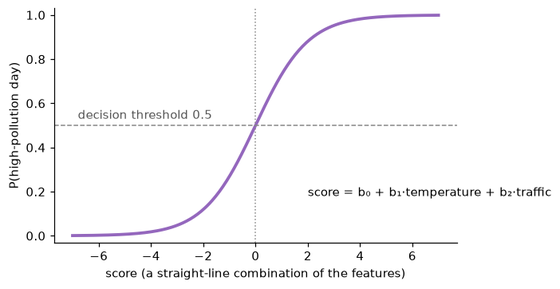">

In [ ]:
# ✍️ Type along: fit a logistic regression to high_train; probabilities for three new days

<details><summary>Code from class</summary>

```python
logit = LogisticRegression(max_iter=1000)
logit.fit(X_train, high_train)

new_days = pd.DataFrame({"temperature": [15, 25, 30], "traffic_intensity": [30, 75, 90]})
print(logit.predict_proba(new_days).round(3))     # columns: P(normal), P(high)
print(logit.predict(new_days))                     # the class, using 0.5
```

</details>

**Predict:** three new days: 15 °C with light traffic (30); 25 °C with fairly heavy traffic (75); 30 °C with heavy traffic (90). Roughly what probability of a high-pollution day do you expect for each, and which class will each get?

In [ ]:
logit = LogisticRegression(max_iter=1000).fit(X_train, high_train)
new_days = pd.DataFrame({"temperature": [15, 25, 30], "traffic_intensity": [30, 75, 90]})
print("P(high):", logit.predict_proba(new_days)[:, 1].round(3), " class:", logit.predict(new_days))

`predict_proba` gives one column per class; column 1 is the probability of a high-pollution day. The cool, quiet day is certain to be normal and the hot, busy day certain to be high. The middle day gets **0.43**: below 0.5, so it is classified *normal*, but only just. Those in-between days are where the model's mistakes will come from, and where the choice of threshold matters (Hour 2).

### Decision boundaries

A classifier splits the feature space into regions, one per class. The line between them is the **decision boundary**. Logistic regression can only draw a **straight** boundary; a random forest builds a **stepped** one from many if/else splits, and can bend it.

<img alt="Training days plotted by temperature and traffic, coloured by class, with the region each model predicts as high shaded red: a straight boundary for logistic regression, a stepped curved boundary for the random forest" src="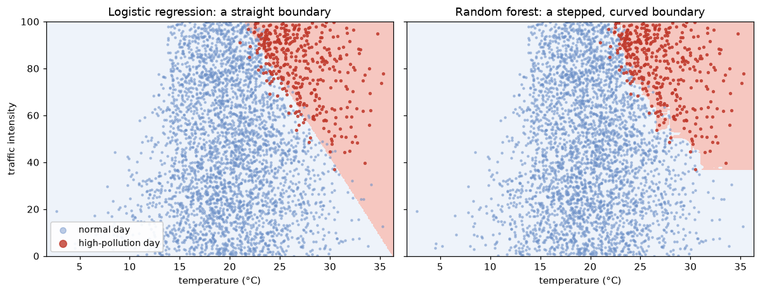">

High-pollution days need **both** warmth and traffic, so the true boundary curves. Notice the **empty corner** at top left: the cold, busy days removed in Week 11. Neither model has seen a single day there, yet each still paints the corner with a class.

### Accuracy, and why it can fool you

**Accuracy** = share of test days classified correctly.

**Predict:** a lazy "model" that **always** says *normal day* never finds a single high-pollution day. What accuracy does it get on our test days?

In [ ]:
always_normal = np.zeros(len(high_test), dtype=int)
print("always 'normal':   ", round(accuracy_score(high_test, always_normal), 3))
print("logistic regression:", round(accuracy_score(high_test, logit.predict(X_test)), 3))

**89 %** for a model that is useless for its purpose. With a rare class, accuracy is dominated by the common class. Logistic regression's 96.8 % is better, but accuracy alone can't tell us **how many high-pollution days it missed**.

### The confusion matrix

A **confusion matrix** counts the four possible outcomes. scikit-learn puts the actual class in rows and the predicted class in columns:

<img alt="A two by two grid: true negatives (normal days predicted normal), false positives (normal days predicted high, false alarms), false negatives (high days predicted normal, missed days), true positives (high days predicted high)" src="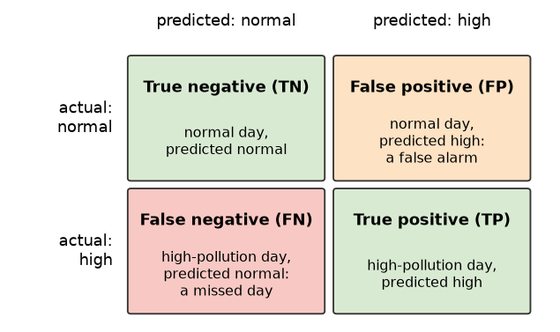">

In [ ]:
cm_logit = confusion_matrix(high_test, logit.predict(X_test))
ConfusionMatrixDisplay(cm_logit, display_labels=["normal", "high"]).plot(cmap="Blues", colorbar=False)
plt.show()

838 normal days and 79 high days were classified correctly. The model raised **8 false alarms** and **missed 22 of the 101 high-pollution days**: more than one in five.

**Your turn:** fit a `RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)` on the same training data, call it `forest`, and print its confusion matrix on the test days. Does it miss fewer high-pollution days than logistic regression?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
forest.fit(X_train, high_train)
print(confusion_matrix(high_test, forest.predict(X_test)))
```
`[[836, 10], [21, 80]]`: the forest misses **21** high days instead of 22, and raises 10 false alarms instead of 8. The two models are almost equally good here: on two features, the straight boundary is already close to the curved one. Which one is "better" depends on which mistake matters more: that is Hour 2.

</details>

### More than two classes: the Week 7 satellite pixels

The same workflow handles **multi-class** problems. In Week 7 you met a table of **3,600 labelled Sentinel-2 pixels** around Cardiff: six bands plus NDVI and NDWI, and a land-cover label from ESA WorldCover. Here a random forest learns to tell **vegetation**, **urban** and **water** apart (no Earth Engine needed: the table is a saved file).

**Before we run this:** the confusion matrix will be 3 × 3. Which two classes do you expect to confuse most often?

In [ ]:
pixels = pd.read_csv(get_data("landcover_cardiff_2021_sample.csv"))
pixels = pixels[pixels["label"] != 0]                       # drop "other" land cover
pixels["land_cover"] = pixels["label"].map({1: "vegetation", 2: "urban", 3: "water"})
bands = ["B2", "B3", "B4", "B8", "B11", "B12", "NDVI", "NDWI"]
P_train, P_test, c_train, c_test = train_test_split(
    pixels[bands], pixels["land_cover"], test_size=0.2, random_state=42, stratify=pixels["land_cover"])

pixel_forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(P_train, c_train)
print("accuracy:", round(accuracy_score(c_test, pixel_forest.predict(P_test)), 3))
ConfusionMatrixDisplay.from_predictions(c_test, pixel_forest.predict(P_test), cmap="Blues", colorbar=False)
plt.show()

About **95 %** of the test pixels are right. Water is almost never confused; most mistakes are **vegetation ↔ urban**: a 10 m pixel in a city often contains both roofs and trees or gardens. `stratify=` keeps the three classes in the same proportions in both sets.

### Takeaways: classification

* A classifier predicts a **class**, usually with a **probability**; logistic regression and random forests are two common choices.
* Define the target **from the training data only** and apply it unchanged to the test data: otherwise test information leaks into the model.
* Our high-pollution class is a **teaching definition** (top 10 % of training days), not an official threshold.
* With a rare class, **accuracy** misleads: "always normal" scores 89 %. Read the **confusion matrix**: false alarms and missed days.

## Hour 2 · Evaluation, deployment and interpretation

### Precision, recall and F1

Three numbers summarise the confusion matrix from the point of view of the class we care about (high-pollution days):

| Score | Formula | The question it answers |
|---|---|---|
| **Precision** | TP / (TP + FP) | when the model says "high", how often is it right? |
| **Recall** | TP / (TP + FN) | of the real high days, how many does it catch? |
| **F1** | 2 × precision × recall / (precision + recall) | one number that is high only if **both** are high |

For logistic regression, TP = 79, FP = 8, FN = 22.

In [ ]:
# ✍️ Type along: precision, recall and F1 of logistic regression, by hand from TP, FP and FN

<details><summary>Code from class</summary>

```python
tp, fp, fn = 79, 8, 22
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print(round(precision, 3), round(recall, 3), round(f1, 3))      # 0.908 0.782 0.84
```

</details>

scikit-learn computes them all in one report, for both classes. Our class of interest is the row `high`:

In [ ]:
print(classification_report(high_test, logit.predict(X_test), target_names=["normal", "high"], digits=3))

Precision **0.91**: when this model warns, it is right nine times in ten. Recall **0.78**: it catches about four high-pollution days in five. The `normal` row looks excellent simply because normal days are easy and common.

**Discuss:** for a **public health warning** service, which mistake costs more: a false alarm or a missed high-pollution day? Would your answer change if each warning **closed a road** or **stopped a factory**?

<details><summary>Answer</summary>

For a health warning, a **missed day** (false negative) is usually worse: vulnerable people are exposed without being told, while a false alarm costs some inconvenience. So we'd want **high recall**, even at some cost in precision. If each warning closes a road or stops a factory, false alarms become expensive, and people stop trusting a service that cries wolf: **precision** matters more. The metric follows the decision, not the other way round. There is no universally "best" model.

</details>

### Moving the decision threshold

`predict` uses a probability threshold of **0.5**. Nothing forces that choice: we can work with `predict_proba` and choose our own.

**Predict:** if we lower the threshold from 0.5 to 0.3, what happens to recall? And to precision?

In [ ]:
p_high = logit.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.05, 0.96, 0.05)
precisions = [precision_score(high_test, (p_high >= t).astype(int)) for t in thresholds]
recalls = [recall_score(high_test, (p_high >= t).astype(int)) for t in thresholds]

plt.plot(thresholds, precisions, "o-", label="precision")
plt.plot(thresholds, recalls, "o-", label="recall")
plt.axvline(0.5, color="grey", ls="--", lw=1)
plt.xlabel("decision threshold on P(high)"); plt.ylabel("score")
plt.title("Lower threshold: more high days caught, more false alarms")
plt.legend(); plt.show()

A lower threshold says "high" more readily: **recall rises** (fewer missed days) and **precision falls** (more false alarms). A higher threshold does the opposite. The model is the same; only the decision rule changes.

**Your turn:** classify the test days with a threshold of **0.3** (`(p_high >= 0.3).astype(int)`) and print the confusion matrix, precision and recall. How many missed days did you save, and how many false alarms did you add?

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
pred_03 = (p_high >= 0.3).astype(int)
print(confusion_matrix(high_test, pred_03))
print(round(precision_score(high_test, pred_03), 3), round(recall_score(high_test, pred_03), 3))
```
`[[830, 16], [10, 91]]`: missed days fall from **22 to 10** (recall 0.78 → **0.90**), false alarms rise from **8 to 16** (precision 0.91 → **0.85**). For a health warning that is probably a good trade.

</details>

### Comparing models across all thresholds: ROC and AUC

The **ROC curve** draws, for every possible threshold, the share of high days caught (true-positive rate = recall) against the share of normal days wrongly flagged (false-positive rate). A model that guesses at random follows the diagonal; a perfect one goes straight to the top-left corner. The **area under the curve (AUC)** is one number: 0.5 is random guessing, 1 is perfect.

In [ ]:
forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train, high_train)
for name, model in [("logistic regression", logit), ("random forest", forest)]:
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(high_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(high_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random guessing")
plt.xlabel("false-positive rate"); plt.ylabel("true-positive rate (recall)"); plt.legend()
plt.show()

Both curves hug the top-left corner (AUC about 0.99). AUC is useful for **comparing models** before you choose a threshold. It doesn't tell you which threshold to use, and with a rare class it can look flattering, because there are so many easy normal days: precision and recall at **your** threshold are what users will experience.

### From a model to predictions in use

Once trained, a model is used on **new days** with the **same features, prepared the same way**. scikit-learn models can be saved to a file with `joblib` and loaded later, without retraining:

In [ ]:
from joblib import dump, load

dump(logit, "high_pm25_model.joblib")
model = load("high_pm25_model.joblib")
tomorrow = pd.DataFrame({"temperature": [26.0], "traffic_intensity": [75.0]})
print("P(high) tomorrow:", model.predict_proba(tomorrow)[:, 1].round(3))

A saved model can run as a **batch** job (e.g. every evening for tomorrow's forecast) or behind a **web service** that answers requests. Either way, every step that came before the model (removing impossible values, the same two features, the same threshold definition) has to come with it.

### Will it work on new data?

A test score describes **days like the training days**. In use, the world moves on: a new site, a hotter year, new traffic patterns, a replaced sensor. When the data that reach a model drift away from its training data (**data drift**), its performance can quietly fall. Deployed models are **monitored** and **retrained**.

**Discuss:** would you trust this model on **another city**, or in **another year**? What, specifically, could go wrong, and what would you check first?

<details><summary>Answer</summary>

* **Different conditions:** a colder city has many cold, busy days, the region our model never saw (the empty corner of the boundary plot).
* **A relative threshold:** "high" means the top 10 % *of our training days*. In a cleaner or dirtier place, the same 79.4 µg/m³ could flag almost no days or a third of them; the users' threshold may be different anyway.
* **Different relationships:** another city has different pollution sources and weather; our model learned one synthetic formula.
* **Optimistic test scores:** neighbouring days (and neighbouring pixels) resemble each other, so a random split gives the model test days very like its training days. Testing on a **later period** or **another place** is the honest check.

First check: score the model on labelled data from the new place or period, and compare its features' ranges with the training data. The guided lab does exactly this.

</details>

### Takeaways: evaluation, deployment and interpretation

* **Precision**: how often a warning is right. **Recall**: how many real events are caught. **F1** balances the two.
* The **decision threshold** is a choice: lower it for recall, raise it for precision, and justify it by the cost of each mistake.
* **ROC/AUC** compares models across all thresholds; the scores at your chosen threshold are what users experience.
* A deployed model needs the same preparation steps, a check on data from where it will be used, and **monitoring for drift**.

### Optional outlook: where would we go next?

*Optional: this is a pointer for after the course, not something you need for the lab.*

Today's models learned from **features someone chose**: two weather and traffic numbers, or a pixel's bands and indices. **Deep learning** uses neural networks with many layers that learn useful features **themselves**, from raw inputs such as whole satellite image patches: early layers pick up simple patterns (edges, textures), deeper layers combine them into shapes and objects.

<img alt="A neural network: raw input on the left feeds layers of nodes that learn simple patterns, then intermediate and abstract features, then predictions or classes on the right; training adjusts the weights to minimise prediction error" src="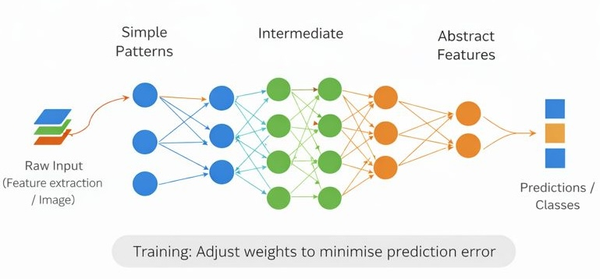">

* **Convolutional neural networks (CNNs)** classify image patches, e.g. land cover from Sentinel-2 patches instead of single pixels.
* **Segmentation networks** such as U-Net label every pixel of an image at once, e.g. water or flood maps.
* The price: much more labelled data, much more computing time, and models that are harder to explain.

If you'd like to look further, three optional notebooks come with this week: `W12_deep_learning_optional.ipynb` (a small CNN, a toy U-Net and a time-series network), `W12_landcover_rf_student.ipynb` (the land-cover classifier with the full Earth Engine sampling step, for those with Earth Engine access) and `W12_unet_water_student.ipynb` (a stretch lab: a U-Net for water on Sentinel-2).

## Transition to the guided lab

**You now know** how to define a class from training data, fit a classifier, read a confusion matrix and precision/recall/F1, move a decision threshold, and question a model's use on new data.

**The guided lab** (`W12_guided_lab_student.ipynb`, two hours) builds a high-pollution day classifier from the cleaned Week 11 data, step by step, and then tests it where it really matters, on data it has never seen:
1. rebuild the cleaned data and split it;
2. define the high-pollution class from the training days;
3. the "always normal" baseline;
4. fit a random forest classifier;
5. its confusion matrix;
6. precision, recall and F1;
7. probabilities and the decision threshold;
8. a year of data from a **warmer city**: does the model still work?
9. save the model, reload it, and decide what to monitor.

## Week 12 takeaways

* A classification target must be **defined** before it can be predicted; define it from the training data and say what it means (and doesn't).
* Judge a classifier by its **mistakes**: confusion matrix, precision, recall, F1, at a threshold chosen for the decision it supports.
* A model's test score describes data like its training data; new places and periods need new evidence.

## Where next

This is the last teaching week of CMT124. Across the module you went from Python strings to a complete, judged machine-learning workflow on environmental data: **clean → split → fit → evaluate → interpret → question**. That last step, asking where a model should not be trusted, is the habit to keep.

Before you leave: rerun this notebook top to bottom and finish any *Your turn* you skipped.

## Optional: explore after class

**Weighting the rare class.** `RandomForestClassifier(..., class_weight="balanced")` tells the forest that each high-pollution day counts as much as nine normal ones. Refit `forest` with it: does recall change? Compare with simply lowering the threshold.

**Which pixel features matter?** Refit `pixel_forest` with only the RGB bands (`["B2", "B3", "B4"]`), then with only `["NDVI", "NDWI"]`. Which three-class problem gets harder, and why might near-infrared and short-wave infrared bands help?

<details><summary>Code</summary>

```python
balanced = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, class_weight="balanced")
balanced.fit(X_train, high_train)
print(classification_report(high_test, balanced.predict(X_test), target_names=["normal", "high"], digits=3))

for cols in [["B2", "B3", "B4"], ["NDVI", "NDWI"]]:
    m = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(P_train[cols], c_train)
    print(cols, round(accuracy_score(c_test, m.predict(P_test[cols])), 3))
```

</details>

## Credits

* The air-quality data are synthetic, generated by the code in the Setup cell for this course.
* Satellite pixel table: contains modified Copernicus Sentinel data 2021, processed in Google Earth Engine; land cover from ESA WorldCover 10 m 2021 v200 (Zanaga et al. 2022), CC BY 4.0.